# Alabama — Adaptive Gaussian Pd/Qd sampling and Julia AC-OPF verification

**Notebook 1 of 2.** Runs the existing Julia verifier and saves **every proposed scenario and its Julia outcome**, including rejected scenarios. No pretrained GridSFM inference or Captum is needed to run this notebook.

**Run next:** `02_alabama_pretrained_gridsfm_captum_explainability.ipynb`. Both notebooks use `samples/gaussian_load_centered/alabama_acopf_labeled_scenarios.npz` and do not depend on in-memory variables from each other.

**Caution:** Rerunning this sampler starts a new experiment and overwrites the scenario NPZ in `OUTPUT_DIR`.

## 1. Environment

In the same Python environment: `python -m pip install numpy matplotlib juliacall nbformat`. In the Julia environment selected by JuliaCall, you need `PowerModels`, `Ipopt`, `JuMP`, and `JSON3`. A working installation from the previous notebook can be reused. Restart the kernel if changing Julia projects.

In [1]:
# import json
# from pathlib import Path

# data_dir = Path("../power_grid/US/gridsfm_data/16h")

# results = []

# for path in data_dir.glob("*_model.json"):
#     with path.open() as f:
#         obj = json.load(f)

#     results.append({
#         "dataset": path.stem,
#         "buses": len(obj.get("bus", {})),
#         "loads": len(obj.get("load", {})),
#         "generators": len(obj.get("gen", {})),
#         "branches": len(obj.get("branch", {})),
#     })

# for r in sorted(results, key=lambda x: x["buses"]):
#     print(
#         f"{r['dataset']:25s} "
#         f"buses={r['buses']:5d} "
#         f"loads={r['loads']:5d} "
#         f"gens={r['generators']:4d} "
#         f"branches={r['branches']:5d}"
#     )

In [2]:
# Uncomment if these Python dependencies are not installed:
# %pip install numpy matplotlib juliacall


## 2. Imports, paths, and original Alabama network

Adjust `DATA_PATH` and `JULIA_SCRIPT` if your notebook is in a different directory. `JULIA_SCRIPT` is the **separate** existing Julia verifier file.

In [3]:
import copy
import csv
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from juliacall import Main as jl

DATA_PATH = Path("../power_grid/US/gridsfm_data/16h/alabama_model.json")
JULIA_SCRIPT = Path("../power_grid/US/topology_solver_pipeline/gridsfm_load_acopf_verifier.jl")
OUTPUT_DIR = Path("samples/gaussian_load_centered")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.is_file(), f"Alabama case not found: {DATA_PATH.resolve()}"
assert JULIA_SCRIPT.is_file(), f"Julia verifier not found: {JULIA_SCRIPT.resolve()}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
print("Data:", DATA_PATH.resolve())
print("Julia verifier:", JULIA_SCRIPT.resolve())
print("baseMVA:", data["baseMVA"])


Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython
Data: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/gridsfm_data/16h/alabama_model.json
Julia verifier: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/topology_solver_pipeline/gridsfm_load_acopf_verifier.jl
baseMVA: 100.0


## 3. Preserve mapping between Python load rows and Julia load IDs

In [4]:
load_ids = [str(k) for k, v in data["load"].items() if int(v.get("status", 1)) == 1]
loads = np.array([[float(data["load"][i]["pd"]),
                   float(data["load"][i]["qd"])] for i in load_ids], dtype=float)
n_loads = len(load_ids)
assert loads.shape == (n_loads, 2) and np.isfinite(loads).all()
print("Active loads:", n_loads, "shape:", loads.shape)
print("Original mean [Pd,Qd]:", loads.mean(axis=0))
print("Original total [Pd,Qd] (p.u.):", loads.sum(axis=0))


Active loads: 494 shape: (494, 2)
Original mean [Pd,Qd]: [0.19233127 0.08193278]
Original total [Pd,Qd] (p.u.): [95.011645   40.47479128]


## 4. Initialize the unchanged Julia PowerModels verifier

In [5]:
jl.include(str(JULIA_SCRIPT.resolve()))
summary_text = jl.GridSFMLoadVerifier.initialize_case(
    str(DATA_PATH.resolve()), json.dumps(load_ids)
)
print("Julia case initialized:", json.loads(str(summary_text)))


Julia case initialized: {'n_buses': 494, 'initialized': True, 'n_loads': 494, 'n_generators': 55, 'n_branches': 864}


## 5. Python wrapper and baseline AC-OPF check

`accepted=True` requires Julia's strict solver statuses. Test the original Alabama case before sampling.

In [6]:
def verify_acopf(candidate_loads):
    """Pass an (n_loads,2) absolute per-unit load matrix to Julia PowerModels."""
    start = time.perf_counter()
    values = np.asarray(candidate_loads, dtype=float)
    if values.shape != loads.shape or not np.isfinite(values).all():
        return {"accepted": False, "status": "INVALID_INPUT", "objective": None,
                "reason": f"Expected finite shape {loads.shape}; got {values.shape}",
                "termination_status": "NOT_RUN", "primal_status": "UNKNOWN",
                "elapsed_s": time.perf_counter() - start}
    try:
        raw = jl.GridSFMLoadVerifier.verify_loads_json(json.dumps(values.tolist()))
        result = json.loads(str(raw))
        result["elapsed_s"] = time.perf_counter() - start
        return result
    except Exception as exc:
        return {"accepted": False, "status": "SOLVER_ERROR", "objective": None,
                "reason": str(exc)[:1000], "termination_status": "ERROR",
                "primal_status": "UNKNOWN", "elapsed_s": time.perf_counter() - start}

print("Verifying the original Alabama case...")
baseline_result = verify_acopf(loads)
print("Baseline:", baseline_result)
if not baseline_result["accepted"]:
    raise RuntimeError("Baseline not confirmed: " + str(baseline_result))


Verifying the original Alabama case...
Baseline: {'reason': '', 'accepted': True, 'status': 'OPF_SOLVED', 'termination_status': 'LOCALLY_SOLVED', 'primal_status': 'FEASIBLE_POINT', 'objective': 198538.08988997107, 'solve_time': 3.3192970752716064, 'elapsed_s': 10.498205791998771}


## 6. Initialize the **additive noise Gaussian** from original data

`base_cov = np.cov(loads, rowvar=False, bias=True)` is calculated directly from Alabama load `[Pd,Qd]`; it is **not** a covariance of multipliers. Gaussian noise is scaled by `INITIAL_SCALE²`.

Formula: `candidate_loads[i] = original_loads[i] + noise[i]`. Adaptive `noise_mu` and `noise_cov` describe perturbations, **not pooled absolute load values**.

In [7]:
SEED = 42
iterations = 10                # Small smoke test; increase cautiously
samples_per_iteration = 10    # Each costs one large Julia AC-OPF solve
alpha = 0.30                 # Accepted-only exponential smoothing
INITIAL_SCALE = 1.0         # Earlier experiments had mixed acceptance at this scale
NONNEGATIVE = True          # Enforce nonnegative Pd and Qd through pair rejection
MAX_RESAMPLE_ROUNDS = 1000
COV_REG = 1e-10             # Numerical stability

rng = np.random.default_rng(SEED)
base_cov = np.cov(loads, rowvar=False, bias=True)
base_cov = 0.5 * (base_cov + base_cov.T)
noise_mu = np.zeros(2)
noise_cov = (INITIAL_SCALE ** 2) * base_cov + np.eye(2) * COV_REG
initial_noise_mu = noise_mu.copy()
initial_noise_cov = noise_cov.copy()

history = []
verification_log = []
# Records for pretrained GridSFM explanations in a separate notebook
explain_candidates = []
explain_labels = []
explain_metadata = []
last_proposed = None
last_applied = None
last_noise = None
first_accepted_loads = None
first_accepted_metadata = None

print("Original data covariance:\n", base_cov)
print("Initial noise mean:", noise_mu)
print("Initial noise std:", np.sqrt(np.diag(noise_cov)))
print("Total proposed scenarios:", iterations * samples_per_iteration)


Original data covariance:
 [[0.00635228 0.00270606]
 [0.00270606 0.00115278]]
Initial noise mean: [0. 0.]
Initial noise std: [0.07970121 0.03395257]
Total proposed scenarios: 100


## 7. Load-centered Gaussian sampler with optional nonnegative pair rejection

Every load has its own center (`loads[i]`). When a pair contains a negative Pd **or** Qd, redraw **the entire noise pair** for that load. This preserves Pd–Qd dependence *within a joint conditional sample*, but the resulting truncated distribution is no longer an unconstrained Gaussian. Failure to draw valid pairs within the limit raises a clear error instead of silently clipping.

In [8]:
def sample_load_centered_gaussian(rng, loads, noise_mu, noise_cov,
                                  n_scenarios, nonnegative=True,
                                  max_rounds=1000):
    """Return proposed absolute loads, realized noise, and draw diagnostics."""
    n = len(loads)
    noise = rng.multivariate_normal(noise_mu, noise_cov, size=(n_scenarios, n),
                                    check_valid="raise")
    candidates = loads[None, :, :] + noise
    initial_invalid = int(np.any(candidates < 0, axis=-1).sum())
    rounds, total_redraws = 0, 0
    if nonnegative:
        invalid = np.any(candidates < 0, axis=-1)
        while invalid.any() and rounds < max_rounds:
            count = int(invalid.sum())
            noise[invalid] = rng.multivariate_normal(noise_mu, noise_cov, size=count,
                                                      check_valid="raise")
            candidates = loads[None, :, :] + noise
            total_redraws += count
            rounds += 1
            invalid = np.any(candidates < 0, axis=-1)
        if invalid.any():
            raise RuntimeError(f"Failed to draw nonnegative load pairs for {invalid.sum()} "
                               f"positions in {max_rounds} rounds; consider a smaller scale")
    assert np.isfinite(candidates).all()
    if nonnegative:
        assert np.all(candidates >= 0)
    return candidates, noise, {
        "total_pairs": int(n_scenarios * n),
        "initial_invalid_pairs": initial_invalid,
        "resampling_rounds": rounds,
        "redrawn_pairs_total": total_redraws,
        "negative_pd_after": int((candidates[..., 0] < 0).sum()),
        "negative_qd_after": int((candidates[..., 1] < 0).sum()),
    }

# Fast numerical test (no Julia solve)
_test_rng = np.random.default_rng(123)
_test_candidates, _test_noise, _test_diag = sample_load_centered_gaussian(
    _test_rng, loads, noise_mu, noise_cov, n_scenarios=1,
    nonnegative=NONNEGATIVE, max_rounds=MAX_RESAMPLE_ROUNDS)
print("Sampler self-check:", _test_candidates.shape, _test_diag)


Sampler self-check: (1, 494, 2) {'total_pairs': 494, 'initial_invalid_pairs': 21, 'resampling_rounds': 2, 'redrawn_pairs_total': 26, 'negative_pd_after': 0, 'negative_qd_after': 0}


## 8. Adaptive loop — sampling, unchanged verifier, accepted-noise update

On each iteration, sample absolute `[Pd,Qd]` around the original loads. Record the Julia result and the magnitude of load changes. If at least one complete scenario is accepted, flatten **its noise pairs only** to update the two-dimensional noise Gaussian; otherwise leave parameters unchanged. Because accepted samples are pooled across loads, this learns a shared noise model, not a bus-specific model.

In [9]:
for iteration in range(iterations):
    sampled, sampled_noise, sampling_diag = sample_load_centered_gaussian(
        rng, loads, noise_mu, noise_cov,
        n_scenarios=samples_per_iteration,
        nonnegative=NONNEGATIVE,
        max_rounds=MAX_RESAMPLE_ROUNDS,
    )
    good_samples_list = []
    good_noise_list = []
    print(f"\nIteration {iteration + 1}: resampled "
          f"{sampling_diag['initial_invalid_pairs']}/{sampling_diag['total_pairs']} "
          f"initial invalid pairs in {sampling_diag['resampling_rounds']} rounds", flush=True)

    for scenario_idx in range(samples_per_iteration):
        candidate_loads = sampled[scenario_idx]
        verification = verify_acopf(candidate_loads)
        deviation = np.abs(candidate_loads - loads)
        total_change_pct = 100.0 * (candidate_loads.sum(axis=0) / loads.sum(axis=0) - 1)
        row = {
            "iteration": iteration + 1,
            "scenario": scenario_idx + 1,
            "pd_change_pct": float(total_change_pct[0]),
            "qd_change_pct": float(total_change_pct[1]),
            "mean_abs_pd_change": float(deviation[:, 0].mean()),
            "mean_abs_qd_change": float(deviation[:, 1].mean()),
            "negative_pd": int((candidate_loads[:, 0] < 0).sum()),
            "negative_qd": int((candidate_loads[:, 1] < 0).sum()),
            **verification,
        }
        verification_log.append(row)
        # Save ALL proposed scenarios (including rejected); Julia labels are for comparison only.
        explain_candidates.append(candidate_loads.astype(np.float32).copy())
        explain_labels.append(int(verification["accepted"]))
        explain_metadata.append((iteration + 1, scenario_idx + 1,
                                 verification["status"],
                                 verification.get("termination_status", "")))
        print(f"  {iteration + 1}/{iterations}, scenario "
              f"{scenario_idx + 1}/{samples_per_iteration}: "
              f"{verification['status']} ({verification.get('termination_status')}, "
              f"{verification['elapsed_s']:.1f}s), "
              f"total Pd change={total_change_pct[0]:+.2f}%", flush=True)
        if verification.get("reason"):
            print("     Reason:", verification["reason"][:350], flush=True)

        if verification["accepted"]:
            good_samples_list.append(candidate_loads.copy())
            good_noise_list.append(sampled_noise[scenario_idx].copy())
            if first_accepted_loads is None:
                first_accepted_loads = candidate_loads.copy()
                first_accepted_metadata = (iteration + 1, scenario_idx + 1)

    accepted_count = len(good_samples_list)
    good_sampled = (np.stack(good_samples_list)
                    if accepted_count else np.empty((0, n_loads, 2), dtype=float))

    if accepted_count:
        accepted_noise = np.stack(good_noise_list).reshape(-1, 2)
        new_mu = accepted_noise.mean(axis=0)
        new_cov = np.cov(accepted_noise, rowvar=False, bias=True)
        noise_mu = (1.0 - alpha) * noise_mu + alpha * new_mu
        noise_cov = (1.0 - alpha) * noise_cov + alpha * new_cov
        noise_cov = 0.5 * (noise_cov + noise_cov.T) + np.eye(2) * COV_REG

    history.append({
        "iteration": iteration + 1,
        "noise_mu": noise_mu.copy(),
        "noise_std": np.sqrt(np.diag(noise_cov)).copy(),
        "noise_cov": noise_cov.copy(),
        "accepted_count": accepted_count,
        "rejected_count": samples_per_iteration - accepted_count,
        "acceptance_rate": accepted_count / samples_per_iteration,
        "updated": bool(accepted_count),
        **sampling_diag,
    })
    last_proposed = sampled.copy()
    last_applied = good_sampled.copy()
    last_noise = sampled_noise.copy()
    # Save after each iteration, so an interrupted Narval session retains data.
    np.savez_compressed(
        OUTPUT_DIR / "alabama_acopf_labeled_scenarios.npz",
        candidates=np.stack(explain_candidates),
        accepted=np.asarray(explain_labels, dtype=np.int64),
        load_ids=np.asarray(load_ids),
        iteration=np.asarray([m[0] for m in explain_metadata]),
        scenario=np.asarray([m[1] for m in explain_metadata]),
        status=np.asarray([m[2] for m in explain_metadata]),
        termination_status=np.asarray([m[3] for m in explain_metadata]),
    )
    print(f"Iteration {iteration + 1}: accepted {accepted_count}/{samples_per_iteration}, "
          f"noise mean={np.round(noise_mu, 6)}, "
          f"noise std={np.round(np.sqrt(np.diag(noise_cov)), 6)}", flush=True)

print("\nFinal proposed:", last_proposed.shape)
print("Final accepted:", last_applied.shape)
print("Overall accepted:", sum(h['accepted_count'] for h in history),
      '/', iterations * samples_per_iteration)



Iteration 1: resampled 191/4940 initial invalid pairs in 4 rounds
  1/10, scenario 1/10: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), total Pd change=+4.45%
  1/10, scenario 2/10: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+8.05%
  1/10, scenario 3/10: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), total Pd change=+0.51%
  1/10, scenario 4/10: OPF_SOLVED (LOCALLY_SOLVED, 1.0s), total Pd change=+3.94%
  1/10, scenario 5/10: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+3.76%
  1/10, scenario 6/10: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+0.07%
  1/10, scenario 7/10: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+0.58%
  1/10, scenario 8/10: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), total Pd change=+4.92%
  1/10, scenario 9/10: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+2.06%
  1/10, scenario 10/10: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), total Pd change=+7.58%
Iteration 1: accepted 10/10, noise mean=[0.002073 0.000883], noise std=[0.078138 0.033287]

Iteration 2: resampled 177/494

## 9. Visualize acceptance and adaptation

Plots show the *noise* distribution parameters (p.u.), not the mean or covariance of original absolute loads.

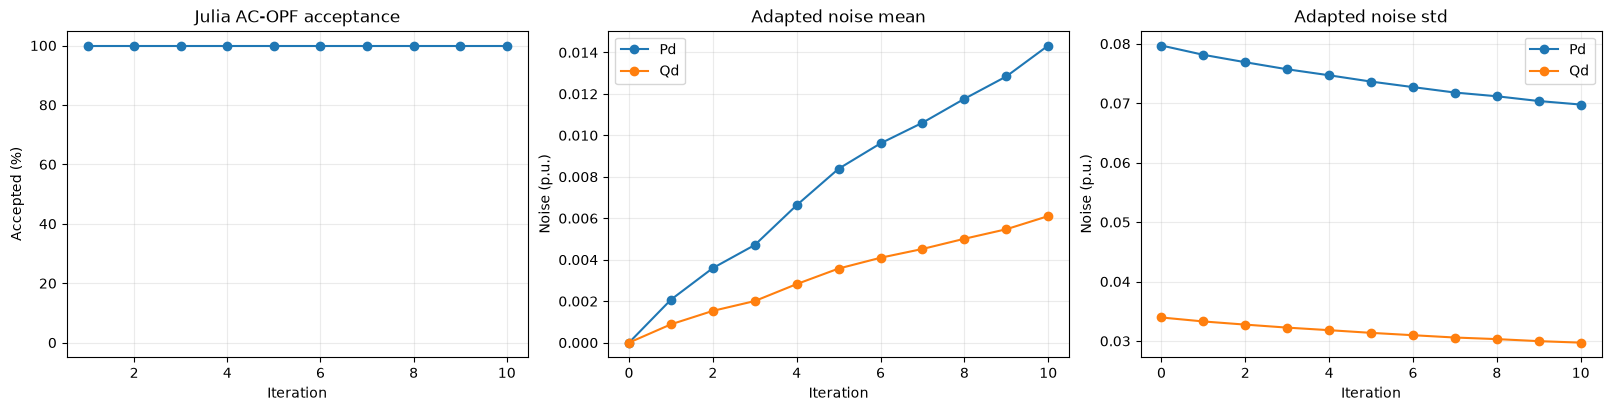

In [10]:
if not history:
    print("No iterations to plot")
else:
    xs = [h["iteration"] for h in history]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
    axes[0].plot(xs, [100*h["acceptance_rate"] for h in history], marker="o")
    axes[0].set(title="Julia AC-OPF acceptance", xlabel="Iteration", ylabel="Accepted (%)", ylim=(-5, 105))
    for j, name in enumerate(["Pd", "Qd"]):
        axes[1].plot([0]+xs, [initial_noise_mu[j]]+[h["noise_mu"][j] for h in history],
                     marker="o", label=name)
        axes[2].plot([0]+xs, [np.sqrt(initial_noise_cov[j,j])]+[h["noise_std"][j] for h in history],
                     marker="o", label=name)
    axes[1].set(title="Adapted noise mean", xlabel="Iteration", ylabel="Noise (p.u.)")
    axes[2].set(title="Adapted noise std", xlabel="Iteration", ylabel="Noise (p.u.)")
    for ax in axes:
        ax.grid(alpha=0.25)
    axes[1].legend()
    axes[2].legend()
    plt.show()


## 10. Plot original, proposed, and accepted absolute loads

For clarity, the scatter uses up to 3,000 randomly chosen load points from the final iteration. All coordinates are in per-unit absolute Pd/Qd.

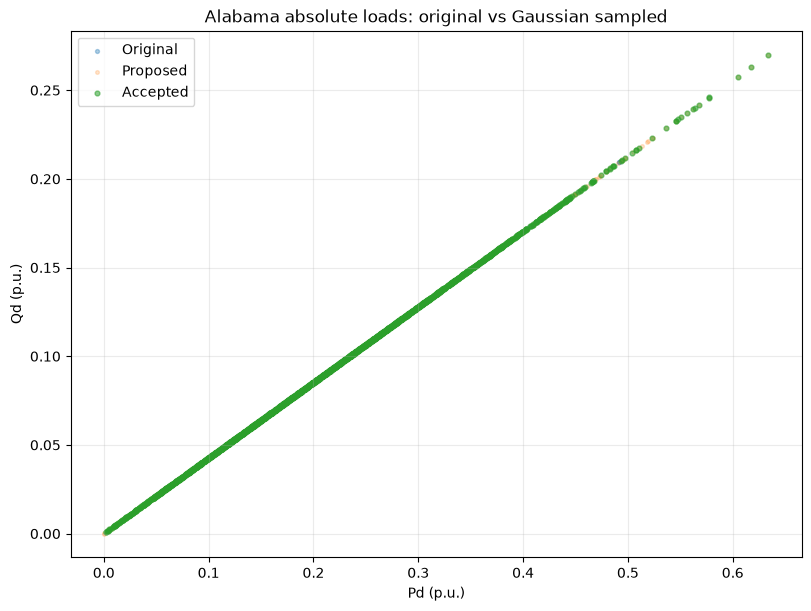

In [11]:
viz_rng = np.random.default_rng(123)
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
for arr, label, size, transparency in [
    (loads, "Original", 8, 0.35),
    (last_proposed.reshape(-1, 2), "Proposed", 7, 0.2),
    (last_applied.reshape(-1, 2), "Accepted", 12, 0.55),
]:
    if len(arr) == 0:
        continue
    idx = viz_rng.choice(len(arr), size=min(3000, len(arr)), replace=False)
    pts = arr[idx]
    ax.scatter(pts[:,0], pts[:,1], s=size, alpha=transparency, label=label, rasterized=True)
ax.set(title="Alabama absolute loads: original vs Gaussian sampled", xlabel="Pd (p.u.)", ylabel="Qd (p.u.)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## 11. Export the verification log, iteration history, and first accepted PowerModels JSON

The accepted JSON preserves all original case data except the active loads' `pd` and `qd`. If no scenario is accepted, no accepted JSON is written.

In [12]:
log_path = OUTPUT_DIR / "verification_log.csv"
with log_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["iteration", "scenario", "accepted", "status", "termination_status",
            "primal_status", "objective", "solve_time", "elapsed_s", "reason",
            "pd_change_pct", "qd_change_pct", "mean_abs_pd_change",
            "mean_abs_qd_change", "negative_pd", "negative_qd"]
    writer = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(verification_log)

history_path = OUTPUT_DIR / "sampling_history.csv"
with history_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["iteration", "accepted_count", "rejected_count", "acceptance_rate",
            "updated", "total_pairs", "initial_invalid_pairs", "resampling_rounds",
            "redrawn_pairs_total", "negative_pd_after", "negative_qd_after",
            "noise_mu_pd", "noise_mu_qd", "noise_std_pd", "noise_std_qd"]
    writer = csv.DictWriter(f, fieldnames=cols)
    writer.writeheader()
    for h in history:
        writer.writerow({**{k: h[k] for k in cols if k in h},
                         "noise_mu_pd": float(h["noise_mu"][0]),
                         "noise_mu_qd": float(h["noise_mu"][1]),
                         "noise_std_pd": float(h["noise_std"][0]),
                         "noise_std_qd": float(h["noise_std"][1])})

if first_accepted_loads is not None:
    case = copy.deepcopy(data)
    for lid, (pd, qd) in zip(load_ids, first_accepted_loads):
        case["load"][lid]["pd"] = float(pd)
        case["load"][lid]["qd"] = float(qd)
    saved_case_path = OUTPUT_DIR / "first_accepted_alabama_model.json"
    with saved_case_path.open("w", encoding="utf-8") as f:
        json.dump(case, f, indent=2)
    print("Accepted model:", saved_case_path, "(iteration/scenario:", first_accepted_metadata, ")")
else:
    print("No accepted scenario to export yet.")

print("Verification log:", log_path)
print("History log:", history_path)


Accepted model: samples/gaussian_load_centered/first_accepted_alabama_model.json (iteration/scenario: (1, 1) )
Verification log: samples/gaussian_load_centered/verification_log.csv
History log: samples/gaussian_load_centered/sampling_history.csv


## Handoff to Notebook 2

When at least one sampling iteration completes, the sampler saves:

`samples/gaussian_load_centered/alabama_acopf_labeled_scenarios.npz`

Contents: `candidates` (full proposed Pd/Qd arrays), `accepted` (Julia solver outcome), `load_ids`, `iteration`, `scenario`, `status`, and `termination_status`.

The explainability notebook does **not** train an Alabama-specific classifier. It uses `gridsfm_open_v1.1.pt` directly. It does not require both solver-label classes and does not invoke Julia. Save this notebook before proceeding.